# Bu Projeden Notlar
- Label Encoding, Target Encoding, Frekans Encoding yaptıktan sonra lineer modellerin büyük sayılı etiket alanın fiyatınında daha büyük olması gerekir gibi bir mantık kurma riski vardır
- bunun için bu encode yöntemleri ile birlikte ağaç tabanlı modeller kullanılır. lineer modeller ve yapay sinir ağları tercih edilmez


# Import Libs

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings("ignore")

# Import Dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/irakozekelly/supply-chain-shipment-pricing-dataset/Supply_Chain_Shipment_Pricing_Dataset.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   id                            10324 non-null  int64  
 1   project code                  10324 non-null  object 
 2   pq #                          10324 non-null  object 
 3   po / so #                     10324 non-null  object 
 4   asn/dn #                      10324 non-null  object 
 5   country                       10324 non-null  object 
 6   managed by                    10324 non-null  object 
 7   fulfill via                   10324 non-null  object 
 8   vendor inco term              10324 non-null  object 
 9   shipment mode                 9964 non-null   object 
 10  pq first sent to client date  10324 non-null  object 
 11  po sent to vendor date        10324 non-null  object 
 12  scheduled delivery date       10324 non-null  object 
 13  d

remove --> id,
target encoding --> project code


# EDA

In [3]:
print(f"Proje kodu:{df["project code"].nunique()}")
print(f"Talep no:{df["pq #"].nunique()}")
print(f"Satış no:{df["po / so #"].nunique()}")
print(f"Teslimat bildirim no:{df["asn/dn #"].nunique()}")

Proje kodu:142
Talep no:1237
Satış no:6233
Teslimat bildirim no:7030


Label Encoding --> Proje kodu 

Remove --> pq #, po / so #,asn/dn #

In [4]:
print(f"Ulkeler: {df["country"].nunique()}")
print("===============================================================================================================")
print(f"Yonetici Kurumlar:{df["managed by"].unique()}")
print("===============================================================================================================")
print(f"Gonderim Sekli: {df["fulfill via"].nunique()} {df["fulfill via"].unique()}")
print("===============================================================================================================")
print(f"Uluslararası Teslim Sekli: {df["vendor inco term"].nunique()} {df["vendor inco term"].unique()}")
print("===============================================================================================================")
print(f"Tasima Modu: {df["shipment mode"].nunique()} {df["shipment mode"].unique()}")
print("===============================================================================================================")
print(f"Urun Grubu: {df["product group"].nunique()} {df["product group"].unique()}")
print("===============================================================================================================")
print(f"Alt Grup: {df["sub classification"].nunique()} {df["sub classification"].unique()}")
print("===============================================================================================================")
print(f"Firma: {df["vendor"].nunique()}")
print("===============================================================================================================")
print(f"Urun Tanımı: {df["item description"].nunique()}")
print("===============================================================================================================")
print(f"Test Tipi: {df["molecule/test type"].nunique()}")
print("===============================================================================================================")
print(f"Marka: {df["brand"].nunique()}")
print("===============================================================================================================")
print(f"Dozajlar: {df["dosage"].nunique()} {df["dosage"].unique()}")
print("===============================================================================================================")
print(f"Dozaj Formu: {df["dosage form"].nunique()} {df["dosage form"].unique()}")
print("===============================================================================================================")
print(f"Paket Bası Tablet Sayısı: {df["unit of measure (per pack)"].nunique()} {df["unit of measure (per pack)"].unique()}")
print("===============================================================================================================")
print(f"Üretim Tesisi: {df["manufacturing site"].nunique()}")

Ulkeler: 43
Yonetici Kurumlar:['PMO - US' 'South Africa Field Office' 'Haiti Field Office'
 'Ethiopia Field Office']
Gonderim Sekli: 2 ['Direct Drop' 'From RDC']
Uluslararası Teslim Sekli: 8 ['EXW' 'FCA' 'DDU' 'CIP' 'DDP' 'CIF' 'N/A - From RDC' 'DAP']
Tasima Modu: 4 ['Air' nan 'Truck' 'Air Charter' 'Ocean']
Urun Grubu: 5 ['HRDT' 'ARV' 'ACT' 'MRDT' 'ANTM']
Alt Grup: 6 ['HIV test' 'Pediatric' 'Adult' 'HIV test - Ancillary' 'ACT' 'Malaria']
Firma: 73
Urun Tanımı: 184
Test Tipi: 86
Marka: 48
Dozajlar: 54 [nan '10mg/ml' '150mg' '30mg' '200mg' '200/50mg' '150/300mg' '300mg' '2g'
 '1mg/ml' '600mg' '25mg' '20mg' '250mg' '400mg' '20/120mg' '50+153mg'
 '600/200/300mg' '100mg' '15mg' '80/20mg/ml' '600mg/2ml' '150/200/30mg'
 '100/25mg' '50mg' '300/200mg' '150/300/200mg' '133.3/33.3mg' '80mg/ml'
 '30/6mg' '20mg/ml' '40mg' '300/150/300mg' '500/25mg' '30/50/6mg'
 '150/300+200mg' '150/30mg' '150/200/40mg' '30mg/ml' '200/300mg'
 '150/300+300mg' '300/300mg' '60/100/12mg' '600/300/300mg' '300/100mg'
 '30

label encoding -->tüm kategorik verilere uygulanacak

In [5]:
df['freight cost (usd)'].value_counts()

freight cost (usd)
Freight Included in Commodity Cost    1442
Invoiced Separately                    239
9736.1                                  36
6147.18                                 27
See DN-304 (ID#:10589)                  16
                                      ... 
20885.78                                 1
2282.57                                  1
16007.06                                 1
1653.78                                  1
4521.5                                   1
Name: count, Length: 6733, dtype: int64

paket ucretine dahil yada değil gibi sınıflandırılabilir

In [6]:
print(f"Kategoriklerin Toplam Sayısı:{df[pd.to_numeric(df['weight (kilograms)'], errors='coerce').isna()]['weight (kilograms)'].value_counts().sum()}")
print("==============================================================================================================================")
print(f"Kategoriklerin Tek Tek Sayısı:{df[pd.to_numeric(df['weight (kilograms)'], errors='coerce').isna()]['weight (kilograms)'].value_counts()}")

Kategoriklerin Toplam Sayısı:3952
Kategoriklerin Tek Tek Sayısı:weight (kilograms)
Weight Captured Separately    1507
See DN-304 (ID#:10589)          16
See ASN-32231 (ID#:13648)       14
See ASN-31750 (ID#:19272)       14
See ASN-28279 (ID#:13547)       13
                              ... 
See DN-4052 (ID#:85005)          1
See DN-4011 (ID#:84426)          1
See DN-3903 (ID#:86131)          1
See DN-3867 (ID#:84968)          1
See DN-4016 (ID#:84996)          1
Name: count, Length: 1300, dtype: int64


# GEDA

<Axes: >

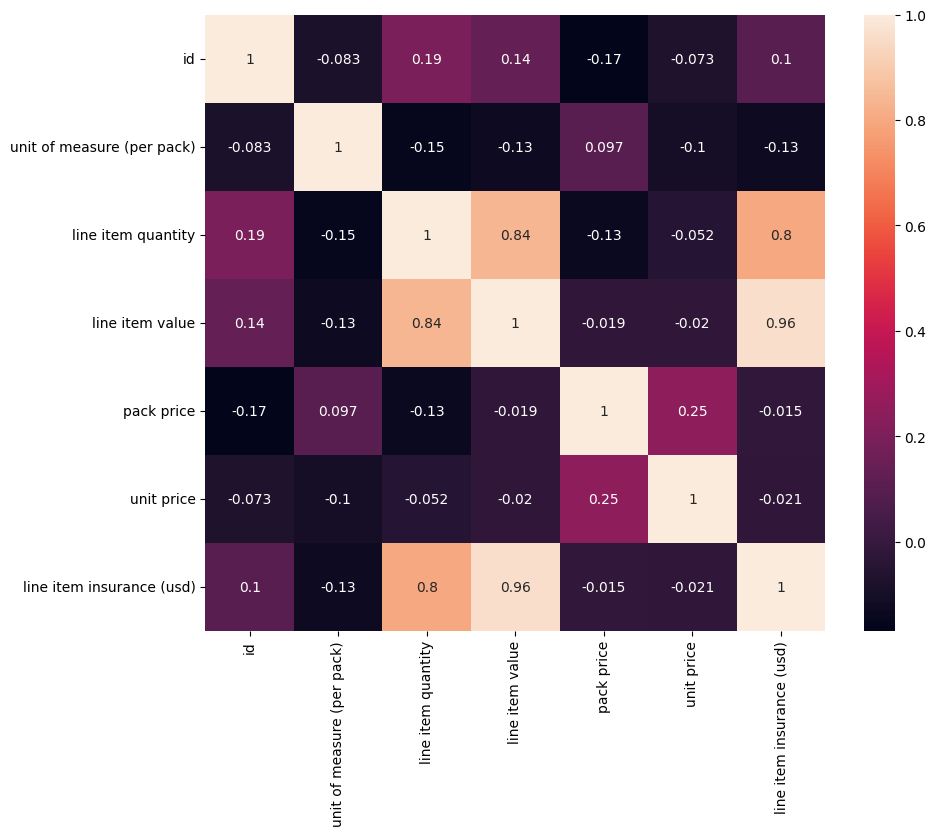

In [7]:
numeric_cols = df.select_dtypes(include=["number"])
matrix = numeric_cols.corr()

plt.figure(figsize=(10,8))
sns.heatmap(matrix,annot = True)